In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import folium

In [12]:
data_path = r"C:\Users\Ā\Documents\python_class\dataset\DC"

In [13]:
crashes = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/DC/DC/Crashes_2024_2025.geojson")
wards = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/DC/DC/Wards_from_2022.geojson")
tracts = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/DC/DC/Census_Tracts_in_2020.geojson")
clusters = gpd.read_file("C:/Users/Ā/Documents/python_class/dataset/DC/DC/Neighborhood_Clusters.geojson")

In [14]:
print("Crashes:", crashes.shape)
print("Wards:", wards.shape)
print("Census tracts:", tracts.shape)
print("Neighborhood clusters:", clusters.shape)

Crashes: (33748, 65)
Wards: (8, 21)
Census tracts: (206, 316)
Neighborhood clusters: (46, 12)


In [15]:
display(wards[["WARD", "NAME", "WARD_ID", "OBJECTID"]].head())
display(tracts[["TRACT", "GEOID", "NAME", "OBJECTID"]].head())
display(clusters[["NAME", "NBH_NAMES", "GIS_ID", "OBJECTID"]].head())

,WARD,NAME,WARD_ID,OBJECTID
0,8,Ward 8,8,1
1,6,Ward 6,6,2
2,7,Ward 7,7,3
3,2,Ward 2,2,4
4,1,Ward 1,1,5


,TRACT,GEOID,NAME,OBJECTID
0,002002,11001002002,Census Tract 20.02,1
1,002101,11001002101,Census Tract 21.01,2
2,002102,11001002102,Census Tract 21.02,3
3,002201,11001002201,Census Tract 22.01,4
4,002202,11001002202,Census Tract 22.02,5


,NAME,NBH_NAMES,GIS_ID,OBJECTID
0,Cluster 16,"Colonial Village, Shepherd Park, North Portal ...",NbhClusPly_1,1
1,Cluster 41,Rock Creek Park,NbhClusPly_2,2
2,Cluster 10,"Hawthorne, Barnaby Woods, Chevy Chase",NbhClusPly_3,3
3,Cluster 17,"Takoma, Brightwood, Manor Park",NbhClusPly_4,4
4,Cluster 40,Walter Reed,NbhClusPly_5,5


In [7]:
print(clusters.columns.tolist())

['WARD', 'NAME', 'REP_NAME', 'WEB_URL', 'REP_PHONE', 'REP_EMAIL', 'REP_OFFICE', 'WARD_ID', 'LABEL', 'STUSAB', 'SUMLEV', 'GEOID', 'GEOCODE', 'STATE', 'OBJECTID', 'GLOBALID', 'CREATED_DATE', 'LAST_EDITED_DATE', 'SHAPEAREA', 'SHAPELEN', 'geometry']


In [16]:
crash_base = crashes[
    [
        "CRIMEID",
        "REPORTDATE",
        "ADDRESS",
        "LATITUDE",
        "LONGITUDE",
        "TOTAL_VEHICLES",
        "TOTAL_PEDESTRIANS",
        "TOTAL_BICYCLES",
        "SPEEDING_INVOLVED",
        "MAJORINJURIES_DRIVER",
        "MINORINJURIES_DRIVER",
        "MAJORINJURIES_PEDESTRIAN",
        "MINORINJURIES_PEDESTRIAN",
        "FATAL_DRIVER",
        "FATAL_PEDESTRIAN",
        "geometry"
    ]
].copy()

crash_base.head()

,CRIMEID,REPORTDATE,ADDRESS,LATITUDE,LONGITUDE,TOTAL_VEHICLES,TOTAL_PEDESTRIANS,TOTAL_BICYCLES,SPEEDING_INVOLVED,MAJORINJURIES_DRIVER,MINORINJURIES_DRIVER,MAJORINJURIES_PEDESTRIAN,MINORINJURIES_PEDESTRIAN,FATAL_DRIVER,FATAL_PEDESTRIAN,geometry
0,49236112798,2024-09-01 09:40:00+00:00,2350 SOUTH DAKOTA AVENUE NE,38.921815,-76.960829,2,0,0,0,0,0,0,0,0,0,POINT Z (-76.96028 38.92187 0)
1,53316040782,2024-12-05 22:00:00+00:00,"INTERSTATE 395 INTERSTATE BN\nWASHINGTON,",38.892032,-77.014022,2,0,0,0,0,0,0,0,0,0,POINT Z (-77.01402 38.89204 0)
2,53619941446,2024-01-03 09:55:00+00:00,1621 MONTANA AVENUE NE,38.921531,-76.981375,2,0,0,0,0,0,0,0,0,0,POINT Z (-76.98138 38.92154 0)
3,53620094830,2024-01-03 10:00:00+00:00,500 INDIANA AVENUE NW,38.894085,-77.018905,1,0,0,0,1,0,0,0,0,0,POINT Z (-77.01891 38.89409 0)
4,53620103358,2024-01-03 11:15:00+00:00,5601 POTOMAC AVENUE NW,38.930057,-77.110398,2,0,0,0,0,1,0,0,0,0,POINT Z (-77.11079 38.93011 0)


In [17]:
crash_ward = gpd.sjoin(
    crash_base,
    wards[["WARD", "NAME", "geometry"]],
    how="left",
    predicate="within"
)

crash_ward[
    ["CRIMEID", "ADDRESS", "WARD", "NAME"]
].head()

,CRIMEID,ADDRESS,WARD,NAME
0,49236112798,2350 SOUTH DAKOTA AVENUE NE,5.0,Ward 5
1,53316040782,"INTERSTATE 395 INTERSTATE BN\nWASHINGTON,",6.0,Ward 6
2,53619941446,1621 MONTANA AVENUE NE,5.0,Ward 5
3,53620094830,500 INDIANA AVENUE NW,6.0,Ward 6
4,53620103358,5601 POTOMAC AVENUE NW,3.0,Ward 3


In [18]:
print("Rows after the spatial join:", len(crash_ward))
print("Crashes without a ward match:", crash_ward["WARD"].isna().sum())

Rows after the spatial join: 33767
Crashes without a ward match: 29


In [19]:
ward_counts = (
    crash_ward
    .dropna(subset=["WARD"])
    .groupby("WARD")
    .size()
    .reset_index(name="crash_count")
)

ward_counts

,WARD,crash_count
0,1.0,2927
1,2.0,5647
2,3.0,1839
3,4.0,2883
4,5.0,5432
5,6.0,4722
6,7.0,5434
7,8.0,4854


In [20]:
ward_map = wards.merge(
    ward_counts,
    on="WARD",
    how="left"
)

ward_map["crash_count"] = ward_map["crash_count"].fillna(0)

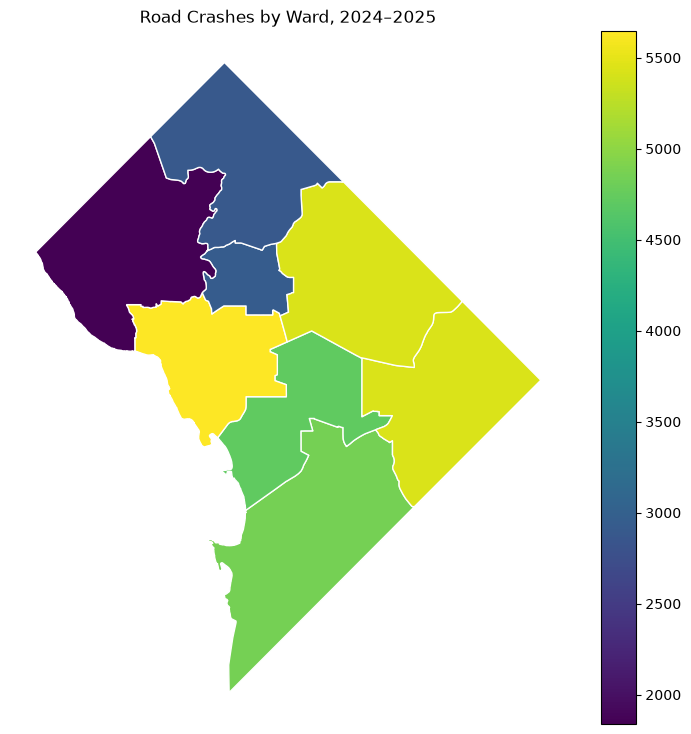

In [21]:
fig, ax = plt.subplots(figsize=(9, 9))

ward_map.plot(
    ax=ax,
    column="crash_count",
    legend=True,
    edgecolor="white"
)

ax.set_title("Road Crashes by Ward, 2024–2025")
ax.set_axis_off()

plt.show()

In [22]:
crash_tract = gpd.sjoin(
    crash_base,
    tracts[["TRACT", "GEOID", "NAME", "geometry"]],
    how="left",
    predicate="within"
)

crash_tract[
    ["CRIMEID", "ADDRESS", "TRACT", "GEOID", "NAME"]
].head()

,CRIMEID,ADDRESS,TRACT,GEOID,NAME
0,49236112798,2350 SOUTH DAKOTA AVENUE NE,011100,11001011100,Census Tract 111
1,53316040782,"INTERSTATE 395 INTERSTATE BN\nWASHINGTON,",980000,11001980000,Census Tract 9800
2,53619941446,1621 MONTANA AVENUE NE,009102,11001009102,Census Tract 91.02
3,53620094830,500 INDIANA AVENUE NW,005900,11001005900,Census Tract 59
4,53620103358,5601 POTOMAC AVENUE NW,000902,11001000902,Census Tract 9.02


In [24]:
print("Rows after the spatial join:", len(crash_tract))
print("Crashes without a census-tract match:", crash_tract["GEOID"].isna().sum())

Rows after the spatial join: 33748
Crashes without a census-tract match: 320


In [25]:
tract_counts = (
    crash_tract
    .dropna(subset=["GEOID"])
    .groupby("GEOID")
    .size()
    .reset_index(name="crash_count")
)

tract_map = tracts.merge(
    tract_counts,
    on="GEOID",
    how="left"
)

tract_map["crash_count"] = tract_map["crash_count"].fillna(0)

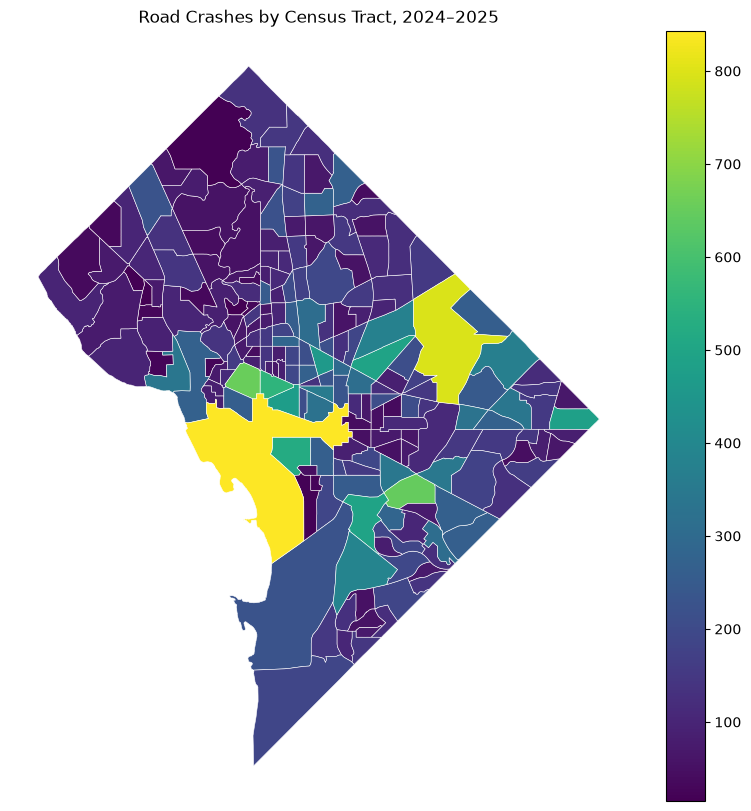

In [26]:
fig, ax = plt.subplots(figsize=(10, 10))

tract_map.plot(
    ax=ax,
    column="crash_count",
    legend=True,
    edgecolor="white",
    linewidth=0.4
)

ax.set_title("Road Crashes by Census Tract, 2024–2025")
ax.set_axis_off()

plt.show()

In [27]:
tract_area = tract_map.to_crs(epsg=32618)

tract_area["area_km2"] = (
    tract_area.geometry.area / 1_000_000
)

tract_area["crashes_per_km2"] = (
    tract_area["crash_count"] /
    tract_area["area_km2"]
)

tract_area[
    ["TRACT", "NAME", "crash_count", "area_km2", "crashes_per_km2"]
].head()

,TRACT,NAME,crash_count,area_km2,crashes_per_km2
0,002002,Census Tract 20.02,219,0.849342,257.846529
1,002101,Census Tract 21.01,175,0.600967,291.197547
2,002102,Census Tract 21.02,272,0.725940,374.686363
3,002201,Census Tract 22.01,72,0.415155,173.429153
4,002202,Census Tract 22.02,62,0.699425,88.644236


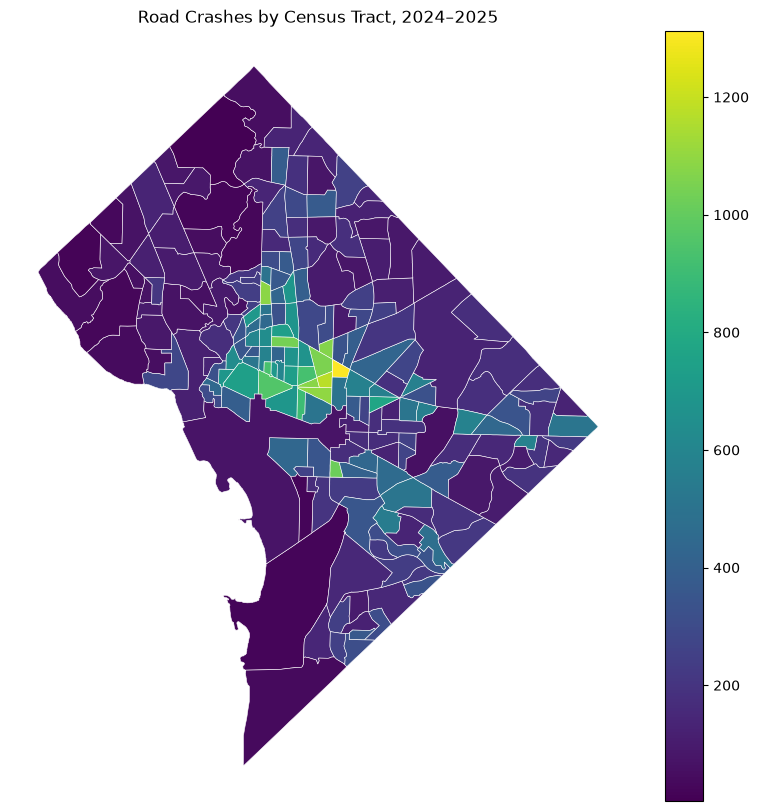

In [28]:
fig, ax = plt.subplots(figsize=(10, 10))

tract_area.plot(
    ax=ax,
    column="crashes_per_km2",
    legend=True,
    edgecolor="white",
    linewidth=0.4
)

ax.set_title("Road Crashes by Census Tract, 2024–2025")
ax.set_axis_off()

plt.show()

In [31]:
tract_area["crashes_per_1000"] = (
    tract_area["crash_count"] /
    tract_area["P0010001"]
    )*1000
tract_area[
    ["TRACT", "NAME", "crash_count", "P0010001", "crashes_per_1000"]
].head()

,TRACT,NAME,crash_count,P0010001,crashes_per_1000
0,002002,Census Tract 20.02,219,4072,53.781925
1,002101,Census Tract 21.01,175,5687,30.771936
2,002102,Census Tract 21.02,272,5099,53.343793
3,002201,Census Tract 22.01,72,3485,20.659971
4,002202,Census Tract 22.02,62,3339,18.568434


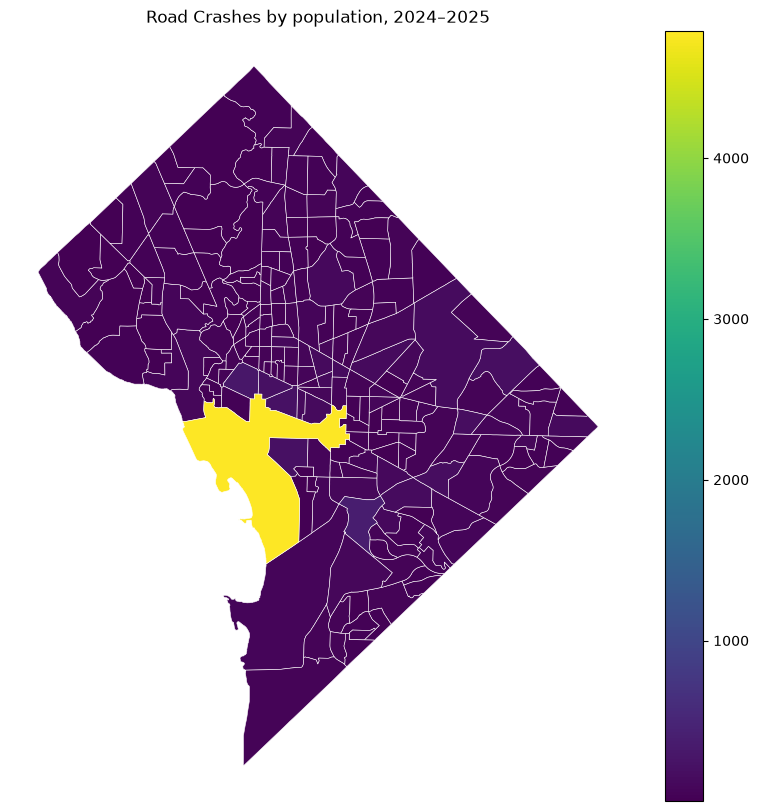

In [34]:
fig, ax = plt.subplots(figsize=(10, 10))

tract_area.plot(
    ax=ax,
    column="crashes_per_1000",
    legend=True,
    edgecolor="white",
    linewidth=0.4
)

ax.set_title("Road Crashes by population, 2024–2025")
ax.set_axis_off()

plt.show()

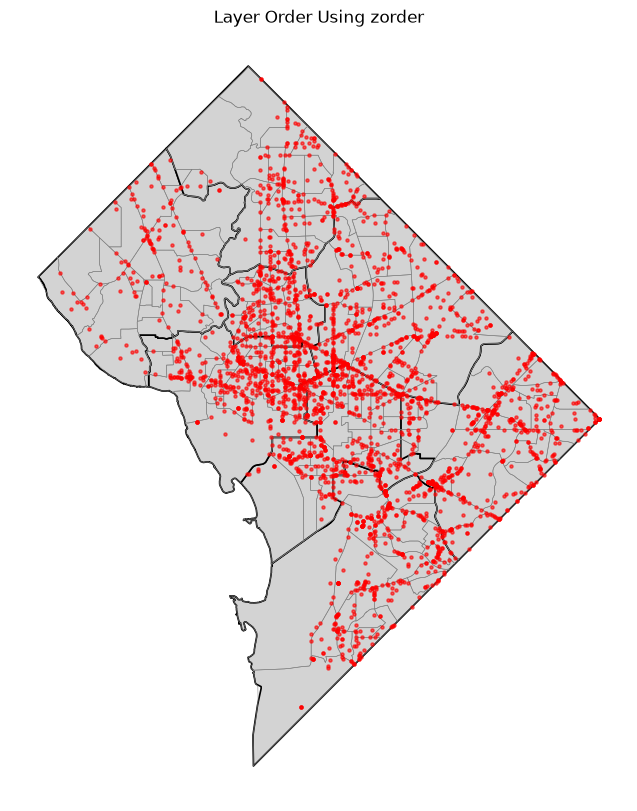

In [35]:
crash_plot = crash_base.sample(
    3000,
    random_state=42
)

ward_z = 2
tract_z = 4
crash_z = 6

fig, ax = plt.subplots(figsize=(10, 10))

wards.plot(
    ax=ax,
    color="lightgray",
    edgecolor="black",
    linewidth=1.2,
    zorder=ward_z
)

tracts.boundary.plot(
    ax=ax,
    color="gray",
    linewidth=0.4,
    zorder=tract_z
)

crash_plot.plot(
    ax=ax,
    color="red",
    markersize=5,
    alpha=0.6,
    zorder=crash_z
)

ax.set_title("Layer Order Using zorder")
ax.set_axis_off()

plt.show()

In [38]:
###class ex 15 

m = folium.Map(
    location=[13.9072, 77.0369],
    zoom_start=11,
    control_scale=True
)

m